# 🛡️ Network Intrusion Detection System (NIDS) - EDA & Data Cleaning
### Dataset: UNSW-NB15 Network Traffic Analysis
**Notebook 1 of 2: Exploratory Data Analysis, Anomaly Detection & Data Preprocessing**

---

## 📌 Executive Summary
A Network Intrusion Detection System (NIDS) monitors network traffic for malicious activities or policy violations. This notebook performs a thorough **Exploratory Data Analysis (EDA)** and **Data Cleaning** on the **UNSW-NB15** dataset, a modern benchmark for cybersecurity research that combines realistic normal background traffic with contemporary simulated attack behaviors across 9 distinct attack categories.

### Key Objectives:
1. **Data Ingestion & Integrity Audit:** Verify schema, column data types, and record shapes for both training and testing partitions.
2. **Missing & Anomaly Analysis:** Inspect null values, infinite values, and examine duplicates in flow records.
3. **Class Distribution Analysis:** Analyze binary target balance (`label`: Normal vs. Attack) and multi-class distribution (`attack_cat`).
4. **Categorical Feature Profiling:** Investigate network protocols (`proto`), services (`service`), and connection states (`state`), cleaning special placeholders (e.g. `'-'`).
5. **Numerical Feature Profiling:** Analyze flow durations, packet volumes, byte loads, and TTL distributions.
6. **Multicollinearity & Correlation Analysis:** Generate high-resolution Pearson correlation heatmaps and identify highly redundant feature pairs ($|r| > 0.95$).
7. **Cleaned Artifact Export:** Produce cleaned datasets ready for leakage-free feature scaling, model training, and evaluation in Notebook 2.


## 1. Environment Setup & Library Imports
Import necessary data manipulation, visualization, and statistical analysis packages. Automatically detect and configure paths so the notebook runs seamlessly in any environment.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure formatting and visualization defaults
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Ensure figures output directory exists
os.makedirs('reports/figures', exist_ok=True)

print("✓ Environment and visualization libraries loaded successfully.")
print(f"✓ Current Working Directory: {os.getcwd()}")


✓ Environment and visualization libraries loaded successfully.
✓ Current Working Directory: C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning


## 2. Dataset Ingestion & Structural Inspection
Load the pre-split training and testing sets: `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv`.
Uses multi-candidate path resolution so it succeeds regardless of working directory.

In [2]:
# Robust multi-location candidate resolution
dataset_candidates = [
    'Training and Testing Sets',
    '../Training and Testing Sets',
    'c:/Network intrusion model/-Network-Intrusion-Detection-Using-Machine-Learning/Training and Testing Sets',
    'c:/Network intrusion model/Training and Testing Sets'
]

dataset_dir = None
for candidate in dataset_candidates:
    if os.path.exists(candidate) and os.path.isfile(os.path.join(candidate, 'UNSW_NB15_training-set.csv')):
        dataset_dir = os.path.abspath(candidate)
        break

if dataset_dir is None:
    raise FileNotFoundError(f"Could not locate 'Training and Testing Sets' in any candidate path: {dataset_candidates}")

train_path = os.path.join(dataset_dir, 'UNSW_NB15_training-set.csv')
test_path = os.path.join(dataset_dir, 'UNSW_NB15_testing-set.csv')

print(f"✓ Training set path: {train_path}")
print(f"✓ Testing set path:  {test_path}")

# Ingest datasets
print("Loading datasets into memory...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print(f"✓ Training dataset shape: {df_train.shape[0]:,} rows x {df_train.shape[1]} columns")
print(f"✓ Testing dataset shape:  {df_test.shape[0]:,} rows x {df_test.shape[1]} columns")
print(f"✓ Total network flow records: {len(df_train) + len(df_test):,}")

# Display first 5 records
df_train.head()


✓ Training set path: C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning\Training and Testing Sets\UNSW_NB15_training-set.csv
✓ Testing set path:  C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning\Training and Testing Sets\UNSW_NB15_testing-set.csv
Loading datasets into memory...
✓ Training dataset shape: 175,341 rows x 45 columns
✓ Testing dataset shape:  82,332 rows x 45 columns
✓ Total network flow records: 257,673


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,14158.9424,8495.3652,0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,8395.1123,503571.3125,2,17,49.9150,15.4329,61.4269,1387.7783,255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,1572.2719,60929.2305,1,6,231.8756,102.7372,17179.5869,11420.9262,255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,62,252,2740.1790,3358.6221,1,3,152.8765,90.2357,259.0802,4991.7847,255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.4495,tcp,-,FIN,10,6,534,268,33.3738,254,252,8561.4990,3987.0598,2,1,47.7503,75.6596,2415.8376,115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


### 2.1 Column Data Types & High-Level Summary
Examine data types across all 45 columns to identify numerical and categorical features.

In [3]:
# Summary table of columns, datatypes, and unique counts
dtypes_summary = pd.DataFrame({
    'Train_Dtype': df_train.dtypes,
    'Train_Unique': df_train.nunique(),
    'Test_Dtype': df_test.dtypes,
    'Test_Unique': df_test.nunique()
})
print("Summary of Columns and Data Types:")
display(dtypes_summary.head(20))
print(f"... and {len(dtypes_summary)-20} more columns.")


Summary of Columns and Data Types:


,Train_Dtype,Train_Unique,Test_Dtype,Test_Unique
id,int64,175341,int64,82332
dur,float64,74039,float64,39888
proto,str,133,str,131
service,str,13,str,13
state,str,9,str,7
spkts,int64,480,int64,420
dpkts,int64,443,int64,436
sbytes,int64,7214,int64,4489
dbytes,int64,6660,int64,4034
rate,float64,76991,float64,40616


... and 25 more columns.


## 3. Data Quality Audit: Missing, Infinite & Duplicate Records
Thoroughly audit the dataset for:
- Explicit missing values (`NaN`/`None`)
- Implicit missing values (e.g. `'-'` or blank strings)
- Infinite numerical values (`np.inf`, `-np.inf`)
- Duplicate flow records (both with and without the `id` column)


In [4]:
# 1. Check explicit null values
train_nulls = df_train.isnull().sum().sum()
test_nulls = df_test.isnull().sum().sum()
print(f"Explicit Missing Values in Training Set: {train_nulls}")
print(f"Explicit Missing Values in Testing Set:  {test_nulls}")

# 2. Check infinite values across numerical columns
num_cols = df_train.select_dtypes(include=[np.number]).columns
train_inf = np.isinf(df_train[num_cols].values).sum()
test_inf = np.isinf(df_test[num_cols].values).sum()
print(f"Infinite Values in Training Set: {train_inf}")
print(f"Infinite Values in Testing Set:  {test_inf}")

# 3. Check duplicate records
raw_dups_train = df_train.duplicated().sum()
content_dups_train = df_train.drop(columns=['id']).duplicated().sum()
print(f"Exact row duplicates (including 'id'): {raw_dups_train}")
print(f"Traffic flow content duplicates (excluding 'id'): {content_dups_train:,} ({content_dups_train/len(df_train)*100:.2f}%)")


Explicit Missing Values in Training Set: 0
Explicit Missing Values in Testing Set:  0
Infinite Values in Training Set: 0
Infinite Values in Testing Set:  0


Exact row duplicates (including 'id'): 0
Traffic flow content duplicates (excluding 'id'): 67,601 (38.55%)


### 💡 Insight on Flow Duplicates in NIDS
In real-world computer networks, automated port scans, brute-force attacks, and periodic heartbeat beacons produce repeated flow records with identical network parameters (packet size, state, flags). Retaining these represents genuine traffic frequency unless specified otherwise. However, keeping `id` would cause synthetic overfitting, so `id` must always be dropped before training.

## 4. Target Variable Analysis: Binary (`label`) & Multi-Class (`attack_cat`)
Analyze the binary target `label` (0 = Normal, 1 = Attack) and the granular attack category distribution `attack_cat`.

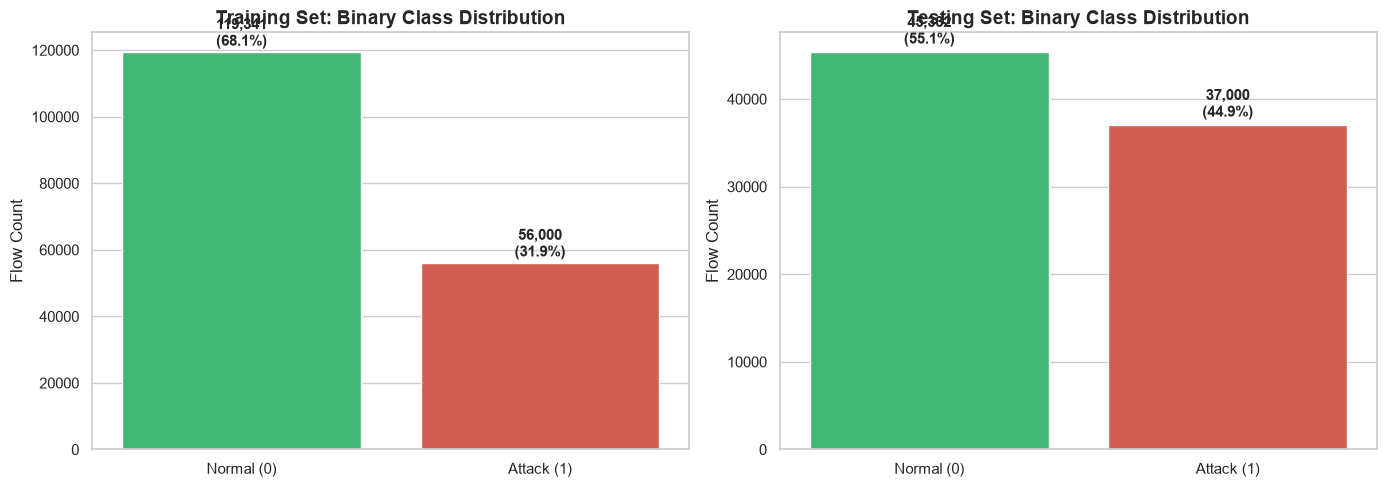

Train target proportions:
 label
1   68.0622
0   31.9378
Name: proportion, dtype: float64

Test target proportions:
 label
1   55.0600
0   44.9400
Name: proportion, dtype: float64


In [5]:
# Binary target breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training binary label
train_label_counts = df_train['label'].value_counts()
train_label_pct = df_train['label'].value_counts(normalize=True) * 100
colors = ['#2ecc71', '#e74c3c']

sns.barplot(x=['Normal (0)', 'Attack (1)'], y=train_label_counts.values, palette=colors, ax=axes[0])
axes[0].set_title("Training Set: Binary Class Distribution", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Flow Count")
for i, v in enumerate(train_label_counts.values):
    axes[0].text(i, v + 2000, f"{v:,}\n({train_label_pct.values[i]:.1f}%)", ha='center', fontweight='bold')

# Testing binary label
test_label_counts = df_test['label'].value_counts()
test_label_pct = df_test['label'].value_counts(normalize=True) * 100

sns.barplot(x=['Normal (0)', 'Attack (1)'], y=test_label_counts.values, palette=colors, ax=axes[1])
axes[1].set_title("Testing Set: Binary Class Distribution", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Flow Count")
for i, v in enumerate(test_label_counts.values):
    axes[1].text(i, v + 1000, f"{v:,}\n({test_label_pct.values[i]:.1f}%)", ha='center', fontweight='bold')

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/class_distribution.png', dpi=300)
plt.show()

print("Train target proportions:\n", train_label_pct)
print("\nTest target proportions:\n", test_label_pct)


### 4.1 Granular Attack Category Profiling (`attack_cat`)
UNSW-NB15 categorizes attacks into 9 classes: *Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, and Worms*.

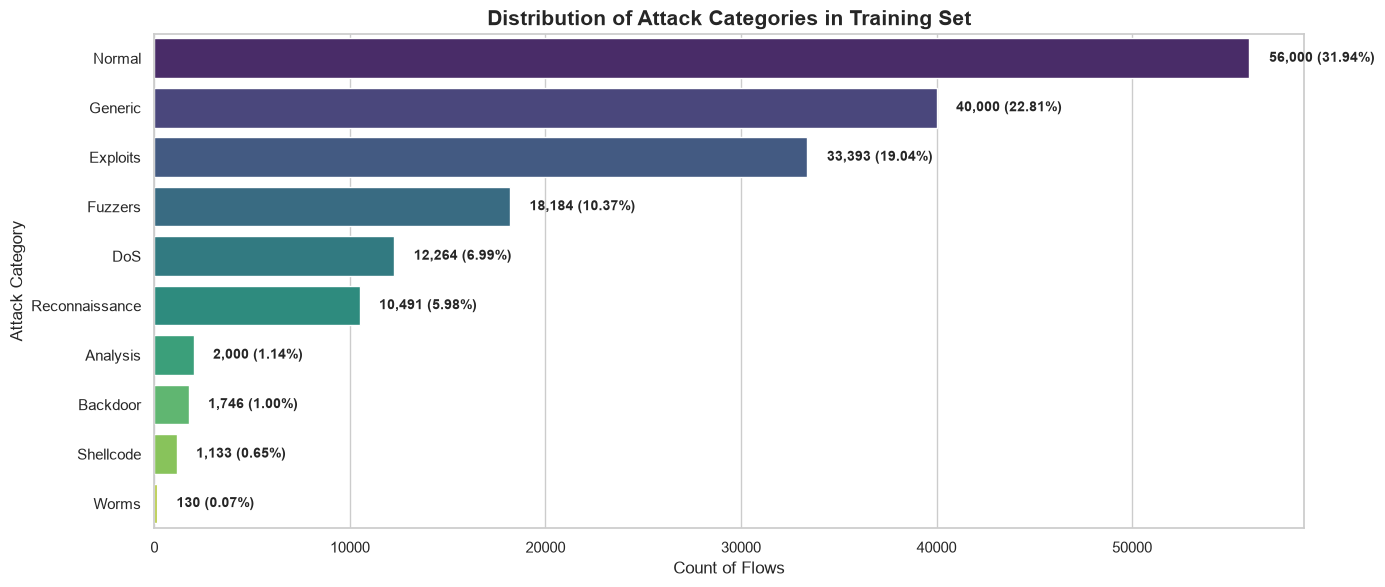

,Train Count,Train %,Test Count,Test %
attack_cat,,,,
Normal,56000,31.9400,37000,44.9400
Generic,40000,22.8100,18871,22.9200
Exploits,33393,19.0400,11132,13.5200
Fuzzers,18184,10.3700,6062,7.3600
DoS,12264,6.9900,4089,4.9700
Reconnaissance,10491,5.9800,3496,4.2500
Analysis,2000,1.1400,677,0.8200
Backdoor,1746,1.0000,583,0.7100
Shellcode,1133,0.6500,378,0.4600


In [6]:
# Attack Category Distribution
attack_order = df_train['attack_cat'].value_counts().index

plt.figure(figsize=(14, 6))
sns.countplot(data=df_train, y='attack_cat', order=attack_order, palette='viridis')
plt.title("Distribution of Attack Categories in Training Set", fontsize=15, fontweight='bold')
plt.xlabel("Count of Flows")
plt.ylabel("Attack Category")

for i, cat in enumerate(attack_order):
    count = (df_train['attack_cat'] == cat).sum()
    pct = count / len(df_train) * 100
    plt.text(count + 1000, i, f"{count:,} ({pct:.2f}%)", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Tabular breakdown
attack_df = pd.DataFrame({
    'Train Count': df_train['attack_cat'].value_counts(),
    'Train %': (df_train['attack_cat'].value_counts(normalize=True)*100).round(2),
    'Test Count': df_test['attack_cat'].value_counts(),
    'Test %': (df_test['attack_cat'].value_counts(normalize=True)*100).round(2)
})
display(attack_df)


## 5. Categorical Feature Profiling & Cleaning
The dataset contains three primary categorical flow attributes:
- `proto`: Transport/Network protocol (e.g., TCP, UDP, UNAS, OSPF)
- `service`: Application layer service (e.g., HTTP, DNS, FTP, SMTP)
- `state`: Connection state indicator (e.g., FIN, INT, CON, REQ)


In [7]:
cat_cols = ['proto', 'service', 'state']

print("Unique values per categorical feature:")
for c in cat_cols:
    print(f"  - {c}: {df_train[c].nunique()} unique in train, {df_test[c].nunique()} unique in test")

# Inspect 'service' value counts
print("\n'service' value counts in Train (Notice '-' placeholder):")
print(df_train['service'].value_counts())

# Inspect 'state' value counts
print("\n'state' value counts in Train:")
print(df_train['state'].value_counts())


Unique values per categorical feature:
  - proto: 133 unique in train, 131 unique in test
  - service: 13 unique in train, 13 unique in test
  - state: 9 unique in train, 7 unique in test

'service' value counts in Train (Notice '-' placeholder):
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

'state' value counts in Train:
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64


### 5.1 Cleaning the `'-'` Placeholder in `service`
In network flow logs, flows that do not match standard port/application protocols have `'-'` as their service. We replace `'-'` with `'none'` to ensure clean semantic representation and prevent downstream parsing issues.

In [8]:
# Clean '-' placeholder in both datasets
df_train['service'] = df_train['service'].replace('-', 'none')
df_test['service'] = df_test['service'].replace('-', 'none')

print("✓ 'service' values successfully sanitized. Top services now:")
print(df_train['service'].value_counts().head(8))


✓ 'service' values successfully sanitized. Top services now:
service
none        94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
Name: count, dtype: int64


### 5.2 Top Protocols vs. Intrusion Status
Compare normal vs. attack proportions across the top network protocols.

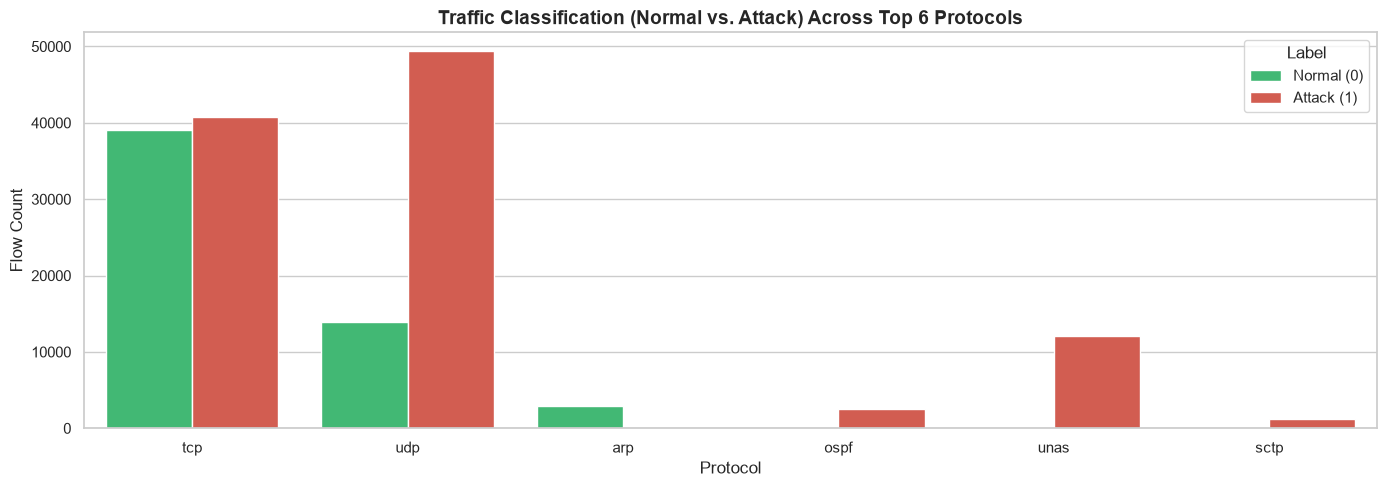

In [9]:
top_protos = df_train['proto'].value_counts().head(6).index
top_proto_df = df_train[df_train['proto'].isin(top_protos)]

plt.figure(figsize=(14, 5))
sns.countplot(data=top_proto_df, x='proto', hue='label', palette=['#2ecc71', '#e74c3c'])
plt.title("Traffic Classification (Normal vs. Attack) Across Top 6 Protocols", fontsize=14, fontweight='bold')
plt.xlabel("Protocol")
plt.ylabel("Flow Count")
plt.legend(title="Label", labels=["Normal (0)", "Attack (1)"])
plt.tight_layout()
plt.show()


## 6. Numerical Feature Distributions & Network Traffic Behavior
Analyze key continuous network features:
- `dur`: Flow duration (seconds)
- `sbytes`, `dbytes`: Source and destination byte volumes
- `rate`: Packet transmission rate
- `sttl`, `dttl`: Source and destination Time-To-Live (crucial for OS footprinting & attack fingerprinting)


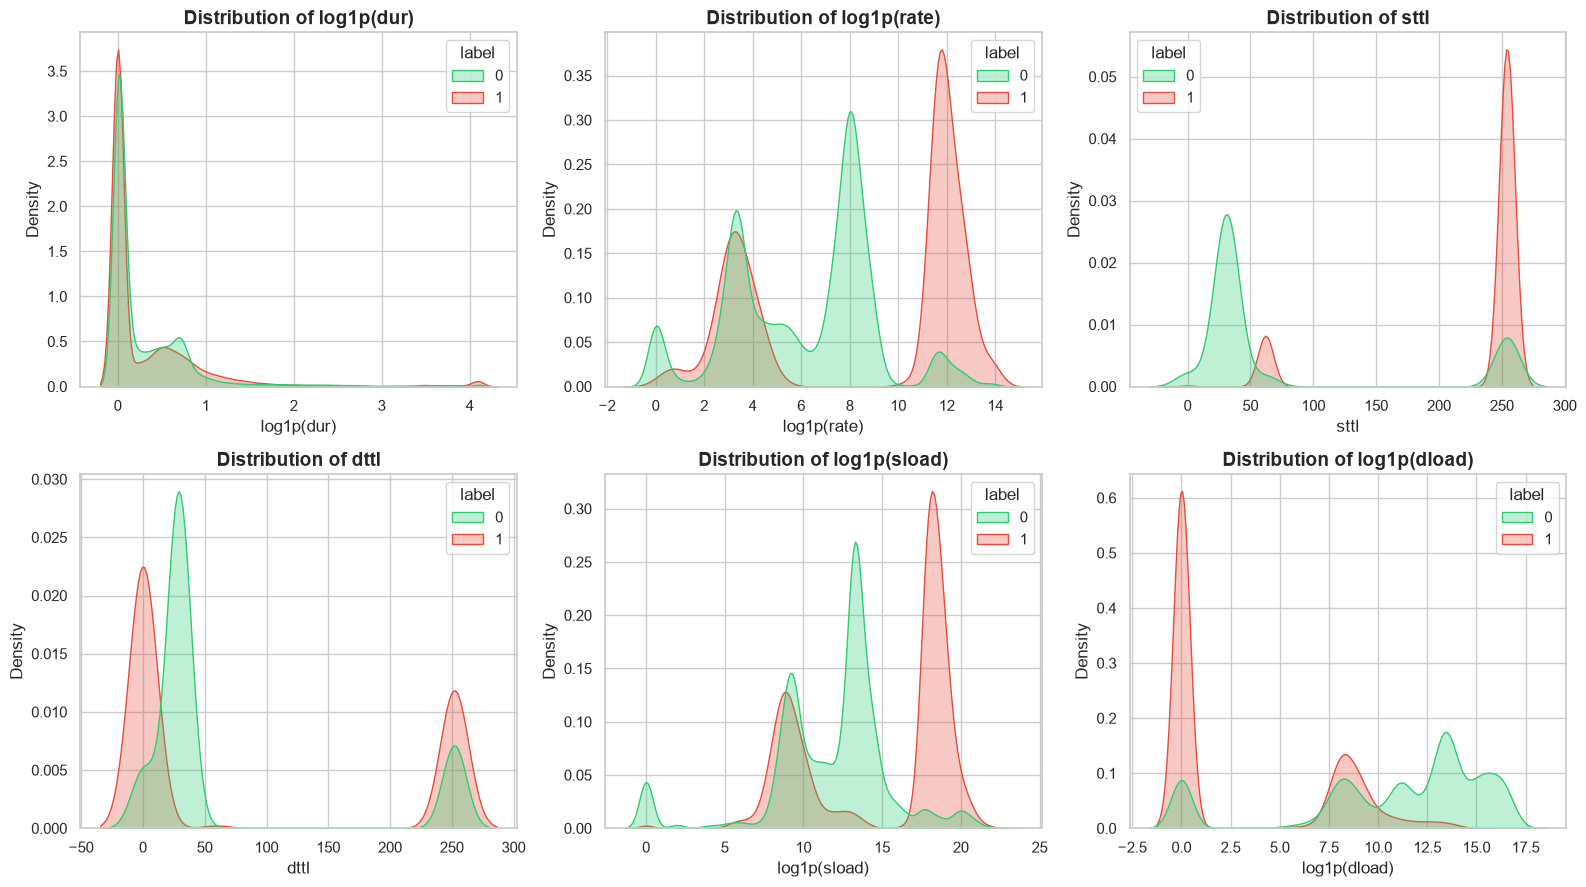

In [10]:
key_num_features = ['dur', 'rate', 'sttl', 'dttl', 'sload', 'dload']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_num_features):
    # Log transform for heavily skewed volume metrics for clearer visualization
    if col in ['dur', 'rate', 'sload', 'dload']:
        log_val = np.log1p(df_train[col])
        sns.kdeplot(data=df_train, x=log_val, hue='label', palette=['#2ecc71', '#e74c3c'], 
                    common_norm=False, fill=True, alpha=0.3, ax=axes[i])
        axes[i].set_title(f"Distribution of log1p({col})", fontweight='bold')
        axes[i].set_xlabel(f"log1p({col})")
    else:
        sns.kdeplot(data=df_train, x=col, hue='label', palette=['#2ecc71', '#e74c3c'], 
                    common_norm=False, fill=True, alpha=0.3, ax=axes[i])
        axes[i].set_title(f"Distribution of {col}", fontweight='bold')
        axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()


### 💡 Key Behavioral Insights:
1. **TTL Disparity (`sttl`):** Attacks frequently originate from distinct operating systems or automated scanning tools with characteristic default TTL values (e.g. 64 vs 254), making `sttl` one of the strongest predictive features.
2. **Transmission Rates (`rate`, `sload`):** DoS and port scans exhibit extremely high packet generation rates compared to typical human browsing sessions.

## 7. Multicollinearity & Correlation Analysis
Calculate Pearson correlation coefficients across all numerical attributes. Multicollinear features ($|r| > 0.95$) add redundancy, inflate model variance, and slow down training without adding new information.

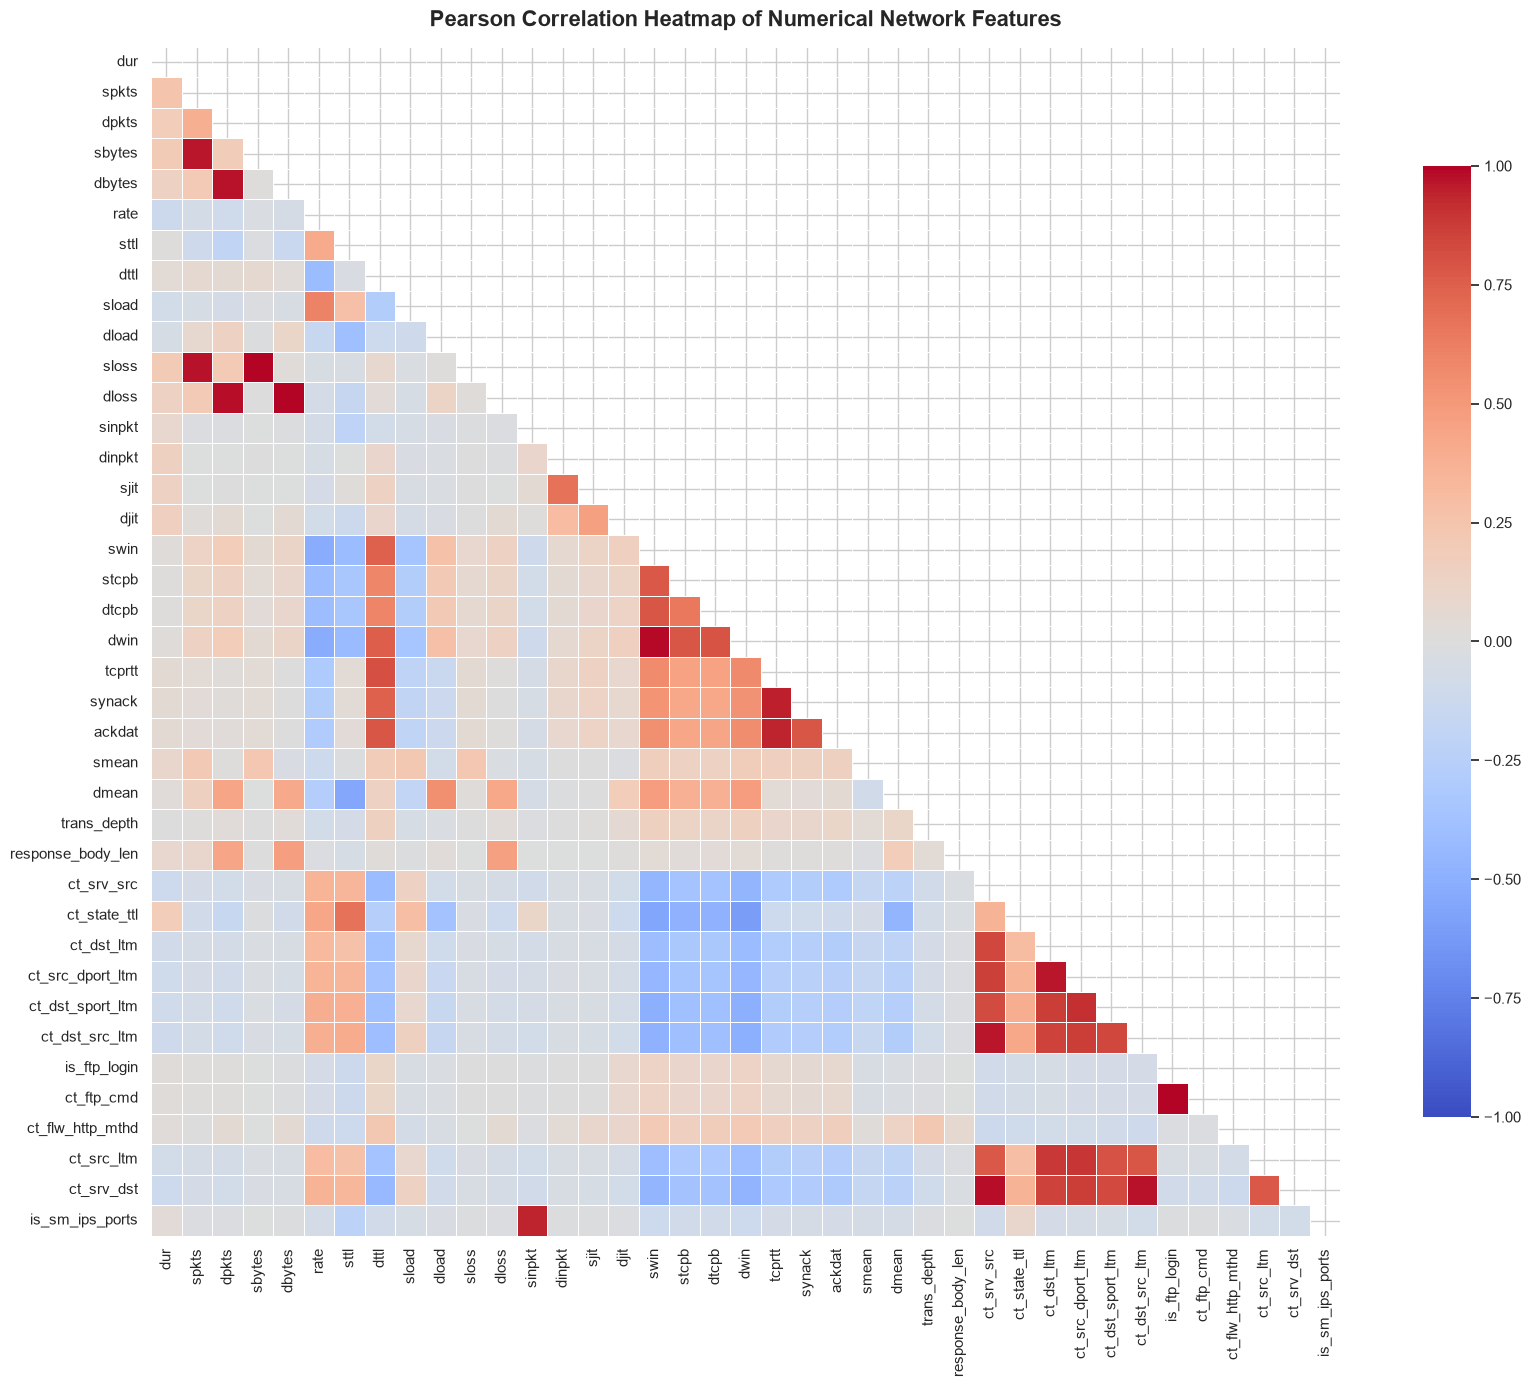

In [11]:
# Select purely numerical features (excluding identifiers and target labels)
num_feature_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c not in ['id', 'label']]

corr_matrix = df_train[num_feature_cols].corr()

# Plot high-resolution correlation heatmap
plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Heatmap of Numerical Network Features", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/correlation_heatmap.png', dpi=300)
plt.show()


### 7.1 Identification of Highly Redundant Feature Pairs ($|r| > 0.95$)

In [12]:
# Find pairs with correlation > 0.95
upper_tri = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = []

for col in upper_tri.columns:
    for row in upper_tri.index:
        val = upper_tri.loc[row, col]
        if val > 0.95:
            high_corr_pairs.append({
                'Feature 1': row,
                'Feature 2': col,
                'Absolute Pearson Correlation': round(val, 4)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values(by='Absolute Pearson Correlation', ascending=False)
print(f"Total feature pairs with |r| > 0.95: {len(high_corr_df)}")
display(high_corr_df)


Total feature pairs with |r| > 0.95: 12


,Feature 1,Feature 2,Absolute Pearson Correlation
9,is_ftp_login,ct_ftp_cmd,1.0000
5,dbytes,dloss,0.9965
3,sbytes,sloss,0.9961
6,swin,dwin,0.9901
10,ct_srv_src,ct_srv_dst,0.9803
4,dpkts,dloss,0.9786
11,ct_dst_src_ltm,ct_srv_dst,0.9724
1,dpkts,dbytes,0.9719
2,spkts,sloss,0.9711
8,ct_srv_src,ct_dst_src_ltm,0.9671


## 8. Summary of Findings & Next Steps (Notebook 2 Roadmap)

### 📊 EDA Summary Findings:
1. **No Missing Data:** Zero missing or infinite values found in either dataset partition.
2. **Sanitized Categoricals:** Replaced ambiguous `'-'` placeholder in `service` with `'none'`.
3. **Data Leakage Safeguards:**
   - `id`: Row index, must be dropped to prevent artificial pattern memorization.
   - `attack_cat`: Sub-class label directly disclosing target class; must be omitted from training features $X$.
4. **Multicollinearity:** Identified 12 redundant feature pairs with $|r| > 0.95$ (such as `is_ftp_login` and `ct_ftp_cmd`, `sbytes` and `sloss`).
5. **Class Balance:** Train split contains 68.1% attack flows and 31.9% normal flows; test split contains 55.1% attack flows and 44.9% normal flows.

---
### ➡️ Next Step:
Proceed to **`02_model_training_and_evaluation.ipynb`** to:
- Construct a scikit-learn `Pipeline` with `StandardScaler` and `OneHotEncoder`.
- Train and tune 4 Machine Learning Classifiers:
  1. Logistic Regression
  2. Decision Tree
  3. Random Forest
  4. Linear Support Vector Machine (LinearSVC)
- Generate Confusion Matrices, ROC Curves, False Alarm Rates ($FAR$), and Feature Importance rankings.
- Serialize the production model artifacts.
